In [1]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

## 1~3 기본 설정
### 1. 가짜 데이터 만들기 :  y = 4 + 3x + ε(잡음)
### 2. 절편용 1열(디자인행렬 만들기) 추가 : X_b = [1, x]
### 3. 정규방정식

In [4]:
# ---------------------------------------------
# 1. 가짜 데이터 만들기: y = 4 + 3x + 잡음
# ---------------------------------------------
np.random.seed(42)                    # 난수 고정 → 매번 같은 데이터
n_samples = 100                       # 샘플 100개
x = 2 * np.random.rand(n_samples, 1)  # 0~1 균등분포 난수 × 2 → 0~2 사이 값, 형태 (100, 1)
y = 4 + 3 * x + np.random.randn(n_samples, 1)  # 정답 = 4 + 3x + 표준정규분포 잡음(오차 ε)
                                      # 참 절편 4, 참 기울기 3 → 이걸 맞히는 게 목표

# ---------------------------------------------
# 2. 절편용 1 열 추가: X_b = [1, x]
# ---------------------------------------------
ones = np.ones((n_samples, 1)) # 1로만 채운 (100 x 1) 행렬 생성
X_b = np.hstack([ones, x])            # 옆으로 붙이기 → (100, 2), 첫 열 1, 둘째 열 x

# ---------------------------------------------
# 3. 정규방정식
# ---------------------------------------------
w_normal = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y   # w = (XᵀX)⁻¹Xᵀy, inv는 역행렬
print("정규방정식 w:", w_normal.ravel())             # ravel: (2,1) → (2,)로 펴서 한 줄 출력


정규방정식 w: [4.21509616 2.77011339]


## 4. 경사하강법 직접 구현

In [5]:
def compute_mse(X, y, w):             # 현재 w의 MSE 계산
    predictions = X @ w               # 예측값 ŷ = Xw, (n, 1)
    errors = predictions - y          # ŷ − y, (n, 1)
    mse = np.mean(errors ** 2)        # 제곱해서 평균
    return mse

def compute_gradient(X, y, w):        # 현재 w에서의 MSE 그래디언트 계산
    n = X.shape[0]                    # 샘플 수 (shape[0] = 행 개수)
    predictions = X @ w               # 예측값
    errors = predictions - y          # ŷ − y
    gradient = (2 / n) * X.T @ errors # ∇MSE = (2/n)Xᵀ(ŷ − y), 형태 (d+1, 1) = w와 같음
    return gradient

def gradient_descent(X, y, learning_rate, n_iterations):  # 경사하강법 본체
    w = np.zeros((X.shape[1], 1))     # w를 0으로 시작, shape[1] = 열 개수
    loss_history = []                 # 반복마다 MSE 기록할 리스트
    for iteration in range(n_iterations):           # 정해진 횟수만큼 반복
        gradient = compute_gradient(X, y, w)        # 1) 현재 위치 기울기 재기
        w = w - learning_rate * gradient            # 2) 반대 방향으로 한 걸음
        loss_history.append(compute_mse(X, y, w))   # 3) 이동 후 MSE 기록
    return w, loss_history            # 최종 w와 학습 기록 반환

w_gd, loss_history = gradient_descent(X_b, y, learning_rate=0.1, n_iterations=1000)  # 학습률 0.1로 1000번
print("경사하강법 w:", w_gd.ravel())                 # 정규방정식 결과와 같은지 비교
print("처음 loss:", round(loss_history[0], 3), "/ 마지막 loss:", round(loss_history[-1], 3))
                                      # [0] = 첫 번째, [-1] = 마지막 → 얼마나 줄었나

# 학습률 비교
for lr in [0.001, 0.1, 1.0]:          # 너무 작음 / 적당 / 너무 큼
    w_lr, history = gradient_descent(X_b, y, learning_rate=lr, n_iterations=100)  # 각각 100번만
    print("학습률", lr, "→ 100회 후 loss:", history[-1])  # 마지막 loss 비교


경사하강법 w: [4.21509616 2.77011339]
처음 loss: 17.935 / 마지막 loss: 0.807
학습률 0.001 → 100회 후 loss: 22.458353412395034
학습률 0.1 → 100회 후 loss: 0.8068834937683229
학습률 1.0 → 100회 후 loss: 6.3057534745722455e+100


#### 5. 실제 데이터로 직접 구현

In [ ]:
dataset = load_diabetes()             # 당뇨병 환자 442명, feature 10개 (나이, BMI, 혈압 등)
X = dataset.data                      # (442, 10)
y_real = dataset.target.reshape(-1, 1) 

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_real,
    test_size=0.2,                    # 20%를 test로
    random_state=42                   # 섞는 방식 고정
)                                     # 회귀라서 stratify 없음 (맞출 클래스 비율이 없음)

# 스케일링: train으로만 fit
scaler = StandardScaler()             # 빈 scaler 생성
scaler.fit(X_train)                   # train의 열별 평균, 표준편차 계산
X_train_scaled = scaler.transform(X_train)  # 그 기준으로 train 변환
X_test_scaled = scaler.transform(X_test)    # 같은 기준으로 test 변환 (test로 fit 안 함)

# 절편용 1 열 추가
X_train_b = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])  # (353, 11)
X_test_b = np.hstack([np.ones((X_test_scaled.shape[0], 1)), X_test_scaled])     # (89, 11)

# 직접 구현
w_my, history = gradient_descent(X_train_b, y_train, learning_rate=0.1, n_iterations=2000)  # w 11개 학습
my_pred = X_test_b @ w_my             # test 예측값, (89, 1)

# sklearn
sk_model = LinearRegression()         # 빈 모델 생성
sk_model.fit(X_train_scaled, y_train) # 학습 (1 열 안 붙임, sklearn이 절편을 알아서 처리)
sk_pred = sk_model.predict(X_test_scaled)  # test 예측

my_rmse = np.sqrt(mean_squared_error(y_test, my_pred))  # RMSE = √MSE, 단위가 y와 같아짐
sk_rmse = np.sqrt(mean_squared_error(y_test, sk_pred))
print("직접 구현 RMSE:", round(my_rmse, 3), "R2:", round(r2_score(y_test, my_pred), 3))
print("sklearn   RMSE:", round(sk_rmse, 3), "R2:", round(r2_score(y_test, sk_pred), 3))
                                      # 두 결과가 거의 같으면 직접 구현이 맞다는 뜻

직접 구현 RMSE: 53.846 R2: 0.453
sklearn   RMSE: 53.853 R2: 0.453


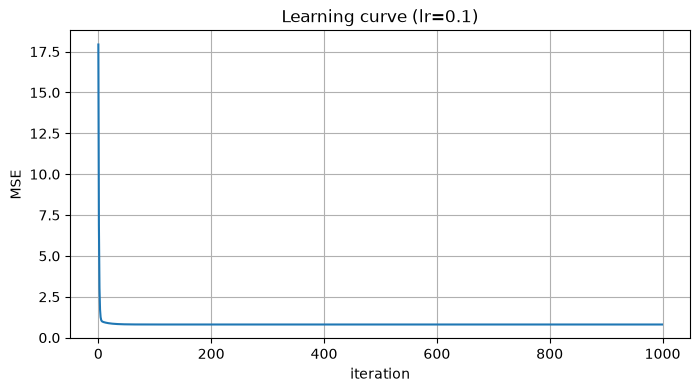

In [7]:
import matplotlib.pyplot as plt

w_gd, loss_history = gradient_descent(X_b, y, learning_rate=0.1, n_iterations=1000)

plt.figure(figsize=(8, 4))            # 그림 크기 (가로, 세로)
plt.plot(loss_history)                # x: 반복 횟수, y: MSE
plt.xlabel("iteration")               # x축 이름
plt.ylabel("MSE")                     # y축 이름
plt.title("Learning curve (lr=0.1)")  # 제목
plt.grid(True)                        # 격자
plt.show()                            # 그림 출력

#### 학습률에 따른 차이 그래프로 시각화하기


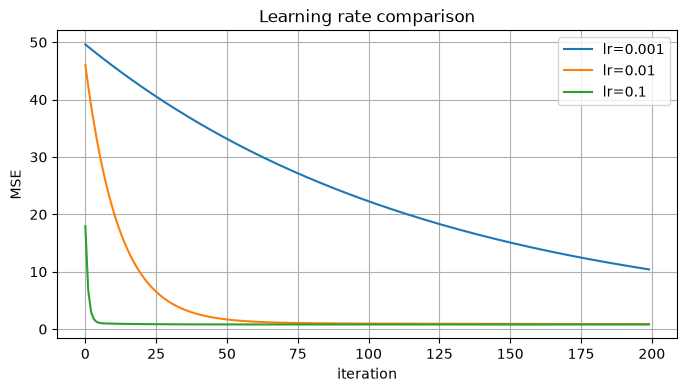

In [9]:
plt.figure(figsize=(8, 4))

for lr in [0.001, 0.01, 0.1]:
    w_lr, history = gradient_descent(X_b, y, learning_rate=lr, n_iterations=200)
    plt.plot(history, label="lr=" + str(lr))   # label: 범례에 표시될 이름

plt.xlabel("iteration")
plt.ylabel("MSE")
plt.title("Learning rate comparison")
plt.legend()                          # 범례 표시
plt.grid(True)
plt.show()

#### 스케일링빼고 학습한 뒤 비교해보기

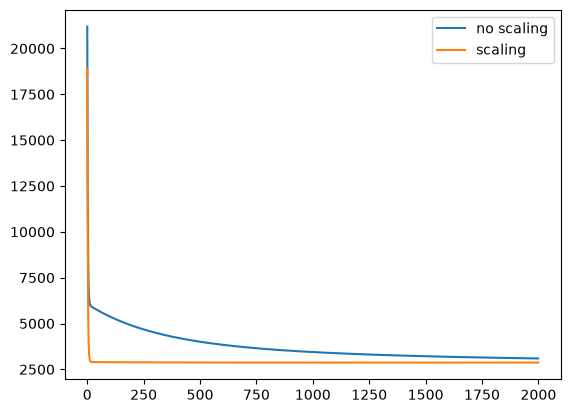

(np.float64(3094.024369131089), np.float64(2868.5690815306493))

In [13]:
# 스케일링 없이
X_train_b_raw = np.hstack([np.ones((X_train.shape[0], 1)), X_train])
w_raw, history_raw = gradient_descent(X_train_b_raw, y_train, learning_rate=0.1, n_iterations=2000)

# 스케일링 있음 (기존)
w_scaled, history_scaled = gradient_descent(X_train_b, y_train, learning_rate=0.1, n_iterations=2000)

# 겹쳐 그리기
plt.plot(history_raw, label="no scaling")
plt.plot(history_scaled, label="scaling")
plt.legend()
plt.show()
history_raw[-1], history_scaled[-1]